# Tarea 6 - Diplomado ML Facultad de Ingeniería

> Edgar Ulises Moreno Chalico
>
> 318192950

1. Aplica k-means al dataset de pingüinos, ¿identifica 3 especies?

2. Aplica clustering jerárquico al dataset CC GENERAL.csv que contiene información de clientes en un banco, ¿cuántos clusters hay? ¿Qué tipo de clientes identificas? Genera el dendrograma

3. ¿Cuántas componentes principales se necesitan para explicar el dataset del titanic en un porcentaje mayor o igual a 80%?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Actividad 1

(342, 9)
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64
 k  inercia  silhouette
 2  565.708       0.532
 3  379.393       0.447
 4  300.400       0.400
 5  232.605       0.379
 6  204.393       0.368
 7  187.029       0.331
 8  170.980       0.296
 9  159.980       0.279
10  149.424       0.284


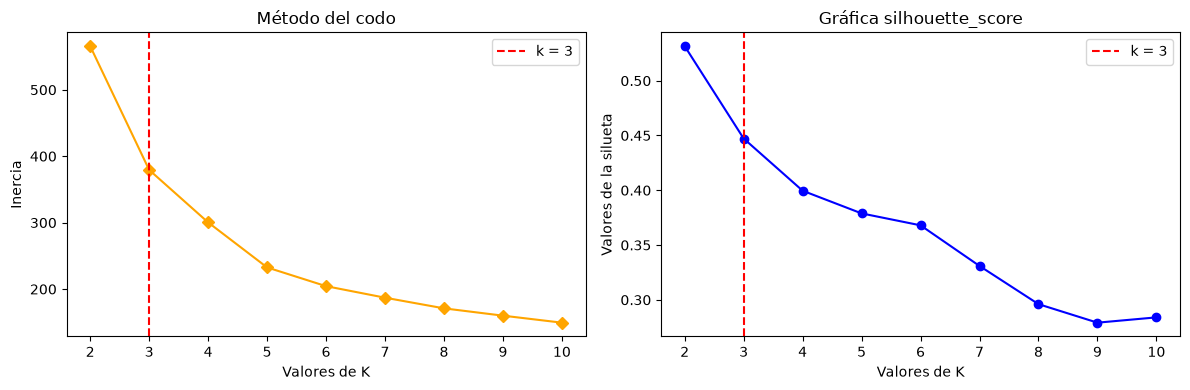

In [2]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

df = pd.read_csv("./penguins.csv")

variables = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

data = df.dropna(subset=variables).copy()
print(data.shape)
print(data["species"].value_counts())

x_scaled = StandardScaler().fit_transform(data[variables])

k_values = list(range(2, 11))
inercias = []
siluetas = []

for k in k_values:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = modelo.fit_predict(x_scaled)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(x_scaled, labels))

resultados_k = pd.DataFrame({"k": k_values, "inercia": inercias, "silhouette": siluetas})
print(resultados_k.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, inercias, marker="D", color="orange")
axes[0].axvline(x=3, color="red", linestyle="--", label="k = 3")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Valores de K")
axes[0].set_ylabel("Inercia")
axes[0].legend()

axes[1].plot(k_values, siluetas, marker="o", color="blue")
axes[1].axvline(x=3, color="red", linestyle="--", label="k = 3")
axes[1].set_title("Gráfica silhouette_score")
axes[1].set_xlabel("Valores de K")
axes[1].set_ylabel("Valores de la silueta")
axes[1].legend()

plt.tight_layout()
plt.show()

In [3]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data["cluster"] = kmeans.fit_predict(x_scaled)

tabla = pd.crosstab(data["species"], data["cluster"])
print("=> Especie real vs cluster")
print(tabla)

mapeo = tabla.idxmax(axis=0)
print(f"\nCluster -> especie: {mapeo.to_dict()}")

data["especie_predicha"] = data["cluster"].map(mapeo)
aciertos = (data["especie_predicha"] == data["species"]).mean()
print(f"Pingüinos asignados a su especie: {aciertos * 100:.2f}%")
print(f"Adjusted Rand Index: {adjusted_rand_score(data['species'], data['cluster']):.3f}")

scaler = StandardScaler().fit(data[variables])
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=variables)
centroides.index = [f"Cluster {i} ({mapeo[i]})" for i in centroides.index]
print("\n=> Centroides")
print(centroides.round(1))

=> Especie real vs cluster
cluster     0    1    2
species                
Adelie     24    0  127
Chinstrap  63    0    5
Gentoo      0  123    0

Cluster -> especie: {0: 'Chinstrap', 1: 'Gentoo', 2: 'Adelie'}
Pingüinos asignados a su especie: 91.52%
Adjusted Rand Index: 0.793

=> Centroides
                       bill_length_mm  bill_depth_mm  flipper_length_mm  \
Cluster 0 (Chinstrap)            47.5           18.8              196.9   
Cluster 1 (Gentoo)               47.5           15.0              217.2   
Cluster 2 (Adelie)               38.2           18.1              188.4   

                       body_mass_g  
Cluster 0 (Chinstrap)       3902.0  
Cluster 1 (Gentoo)          5076.0  
Cluster 2 (Adelie)          3584.7  


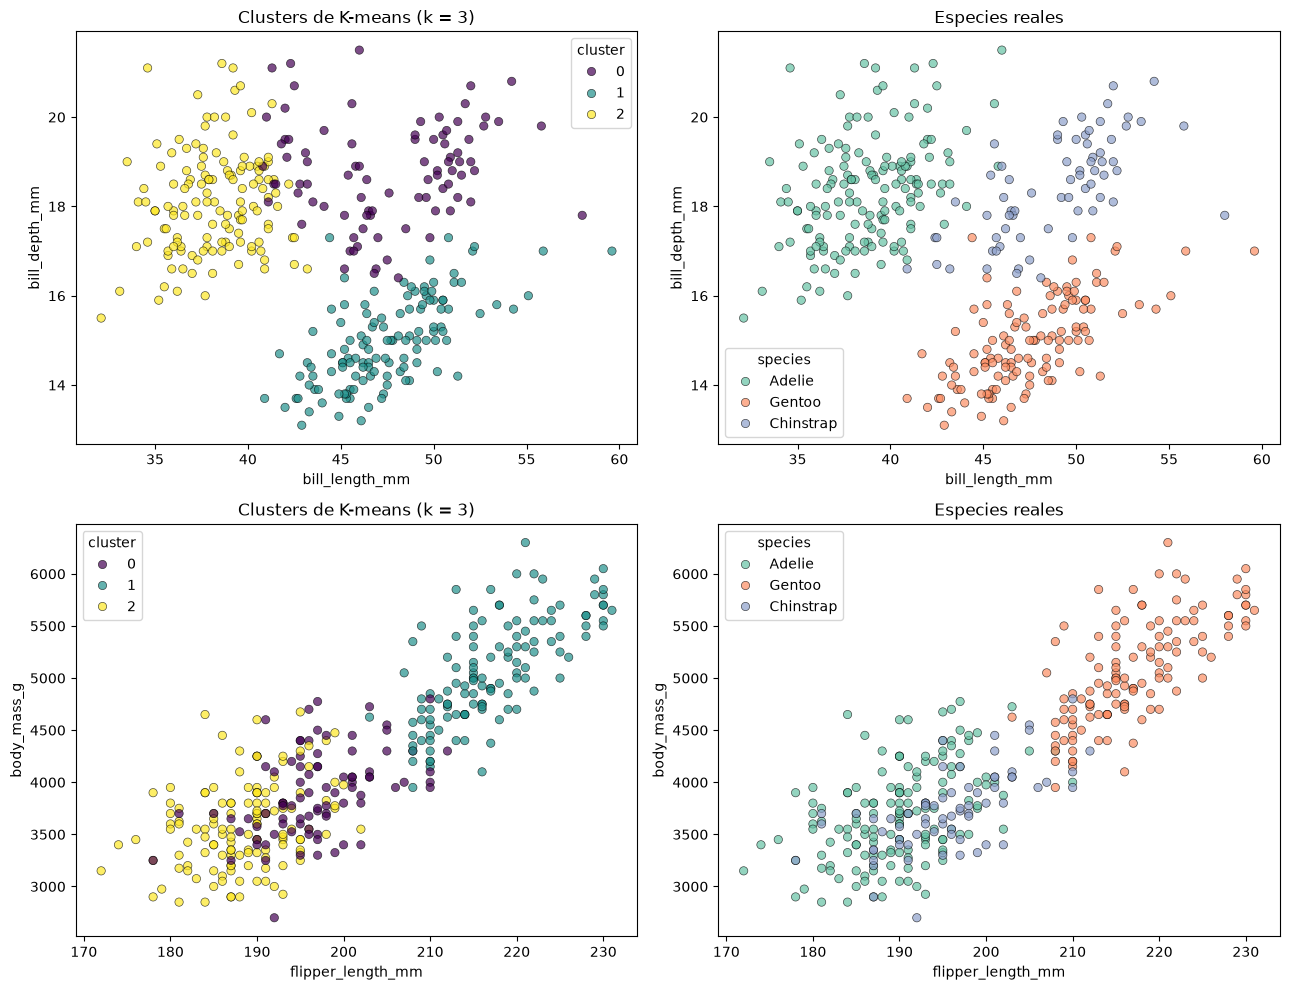

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for fila, (eje_x, eje_y) in enumerate([("bill_length_mm", "bill_depth_mm"), ("flipper_length_mm", "body_mass_g")]):
    sns.scatterplot(data=data, x=eje_x, y=eje_y, hue="cluster", palette="viridis", alpha=0.7, edgecolor="black",
                    ax=axes[fila, 0])
    axes[fila, 0].set_title("Clusters de K-means (k = 3)")

    sns.scatterplot(data=data, x=eje_x, y=eje_y, hue="species", palette="Set2", alpha=0.7, edgecolor="black",
                    ax=axes[fila, 1])
    axes[fila, 1].set_title("Especies reales")

plt.tight_layout()
plt.show()

**K-means con k = 3 identifica las 3 especies razonablemente bien**: el 91.5% de los pingüinos cae en el cluster de su especie (ARI aprox. 0.79).

- **Gentoo** se separa perfectamente (123 de 123): son mucho más pesados, con aletas más largas y pico menos profundo.
- **Adelie** queda casi todo en su cluster (127 de 151), pero 24 se van al cluster de Chinstrap.
- **Chinstrap** tiene 63 de 68 en su cluster. Adelie y Chinstrap tienen casi el mismo peso, aletas y profundidad de pico; solo se distinguen por el **largo del pico** (Chinstrap lo tiene más largo), por eso se mezclan en la frontera.

La silueta es máxima con k = 2 (0.53 vs 0.45 con k = 3), porque Adelie y Chinstrap juntos forman un grupo muy compacto frente a Gentoo. Es decir, sin conocer las especies, los datos sugieren 2 grupos; el tercero aparece al fijar k = 3.

## Actividad 2

In [5]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv("./CC GENERAL.csv")
print(df.shape)
print(df.isna().sum()[df.isna().sum() > 0])

df = df.drop(columns=["CUST_ID"])

df["MINIMUM_PAYMENTS"] = df["MINIMUM_PAYMENTS"].fillna(df["MINIMUM_PAYMENTS"].median())
df["CREDIT_LIMIT"] = df["CREDIT_LIMIT"].fillna(df["CREDIT_LIMIT"].median())

columnas_log = [c for c in df.columns if "FREQUENCY" not in c and c not in ["PRC_FULL_PAYMENT", "TENURE"]]
x = df.copy()
x[columnas_log] = np.log1p(x[columnas_log])

x_scaled = StandardScaler().fit_transform(x)

z = linkage(x_scaled, method="ward")

print("Distancias de las últimas 10 fusiones:")
print(z[-10:, 2].round(1)[::-1])

(8950, 18)
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64
Distancias de las últimas 10 fusiones:
[247.3 183.  150.4 103.2 101.7  95.7  86.2  85.2  77.1  75.2]


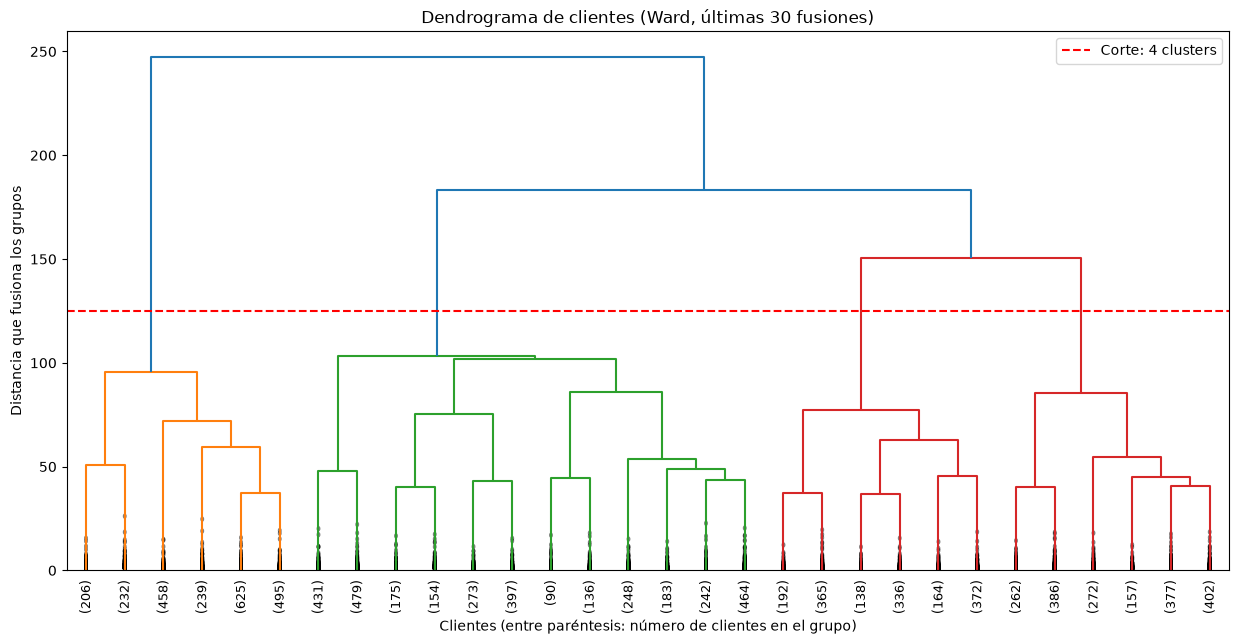

In [6]:
plt.figure(figsize=(15, 7))
dendrogram(z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.axhline(y=125, color="red", linestyle="--", label="Corte: 4 clusters")
plt.title("Dendrograma de clientes (Ward, últimas 30 fusiones)")
plt.xlabel("Clientes (entre paréntesis: número de clientes en el grupo)")
plt.ylabel("Distancia que fusiona los grupos")
plt.legend()
plt.show()

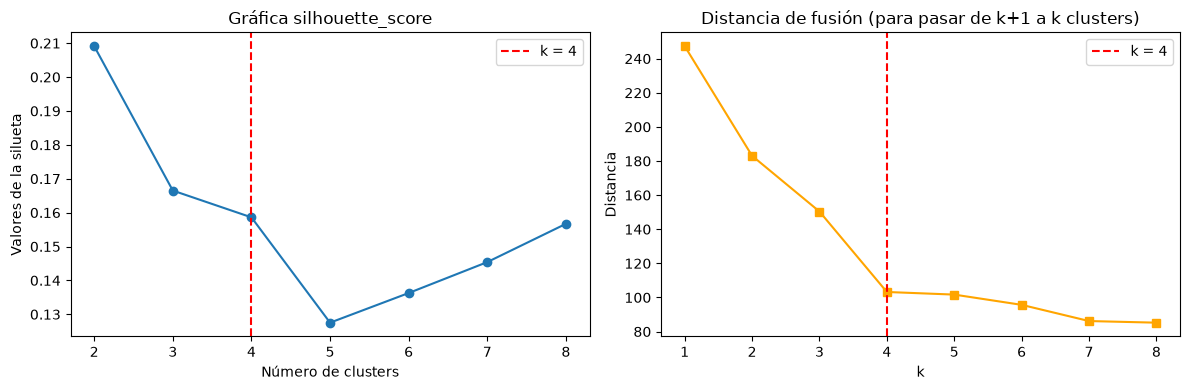

 k  silhouette
 2       0.209
 3       0.167
 4       0.159
 5       0.128
 6       0.136
 7       0.145
 8       0.157


In [7]:
ks = range(2, 9)
siluetas = []
for k in ks:
    etiquetas = fcluster(z, t=k, criterion="maxclust")
    siluetas.append(silhouette_score(x_scaled, etiquetas, sample_size=3000, random_state=0))

saltos = z[::-1, 2][:len(ks) + 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(ks), siluetas, marker="o")
axes[0].axvline(x=4, color="red", linestyle="--", label="k = 4")
axes[0].set_title("Gráfica silhouette_score")
axes[0].set_xlabel("Número de clusters")
axes[0].set_ylabel("Valores de la silueta")
axes[0].legend()

axes[1].plot(range(1, len(saltos) + 1), saltos, marker="s", color="orange")
axes[1].axvline(x=4, color="red", linestyle="--", label="k = 4")
axes[1].set_title("Distancia de fusión (para pasar de k+1 a k clusters)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Distancia")
axes[1].legend()

plt.tight_layout()
plt.show()

print(pd.DataFrame({"k": list(ks), "silhouette": siluetas}).round(3).to_string(index=False))

In [8]:
def interpret(value: float | int) -> str:
    if value > 0.40:
        return "HIGH"
    elif value < -0.40:
        return "LOW"
    else:
        return "MID"


df["Cluster"] = fcluster(z, t=4, criterion="maxclust")
print(df["Cluster"].value_counts().sort_index())

clave = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
         "PURCHASES_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "PURCHASES_TRX", "CREDIT_LIMIT", "PAYMENTS",
         "PRC_FULL_PAYMENT"]

print("\n=> Mediana por cluster")
print(df.groupby("Cluster")[clave].median().round(2).T)

average = df[clave].mean()
cluster_resume = df.groupby("Cluster")[clave].mean()
relative_diff = (cluster_resume - average) / average
print("\n=> Comparación de cada cluster con el promedio")
print(relative_diff.map(interpret).T)

Cluster
1    2255
2    3272
3    1567
4    1856
Name: count, dtype: int64

=> Mediana por cluster
Cluster                       1        2        3        4
BALANCE                 1445.38    89.40   659.12  2012.61
PURCHASES                  0.00   359.34  1903.66   617.85
ONEOFF_PURCHASES           0.00     0.00   999.08   271.51
INSTALLMENTS_PURCHASES     0.00   157.90   622.74   190.26
CASH_ADVANCE            1191.75     0.00     0.00  1254.71
PURCHASES_FREQUENCY        0.00     0.50     1.00     0.58
CASH_ADVANCE_FREQUENCY     0.25     0.00     0.00     0.25
PURCHASES_TRX              0.00     7.00    28.00    11.00
CREDIT_LIMIT            3000.00  2500.00  5500.00  4500.00
PAYMENTS                 763.12   447.84  1718.22  1541.56
PRC_FULL_PAYMENT           0.00     0.00     0.08     0.00

=> Comparación de cada cluster con el promedio
Cluster                    1     2     3     4
BALANCE                  MID   LOW   MID  HIGH
PURCHASES                LOW   MID  HIGH   MID
ONEOF

**Hay 4 clusters.** En el dendrograma, las últimas tres fusiones ocurren a distancias muy grandes (247, 183 y 150) y la siguiente baja a 103: cortar la línea en ese hueco deja 4 grupos. La silueta es baja para todos los k (aprox. 0.16–0.21, clusters con fronteras difusas, común en datos de clientes) y casi no cambia entre 3 y 4, así que se elige 4 porque separa un tipo de cliente más con sentido.

Tipos de clientes:

1. **Clientes de avances en efectivo (~2,255)**: no hacen compras con la tarjeta (mediana de compras = 0), pero usan el *cash advance* (mediana aprox. 1,190) y mantienen un saldo alto. Usan la tarjeta como fuente de préstamos.
2. **Compradores pequeños a plazos (~3,272)**: saldo muy bajo, compras pequeñas sobre todo en mensualidades, sin avances en efectivo y límite de crédito bajo; pagan el total más seguido que el promedio (22% vs 15%). Son los clientes de bajo uso y bajo riesgo.
3. **Grandes compradores activos (~1,567)**: compran casi todos los meses (frecuencia aprox. 1), tanto de contado como a plazos, con los montos, número de transacciones, pagos y límite de crédito más altos (aprox. 6,070 en promedio); son los que más liquidan el saldo completo (30%). Son los clientes más valiosos.
4. **Clientes que lo usan todo / "revolventes" (~1,856)**: el saldo más alto, compran y además piden avances en efectivo, pagan mucho pero rara vez el total. Son rentables por intereses pero son los de mayor riesgo.

## Actividad 3

In [9]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("./titanicData.csv")

df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

X = pd.get_dummies(df.drop(columns=["Survived"]), columns=["Sex", "Embarked"], drop_first=True, dtype=int)
print(X.columns.tolist())

x_scaled = StandardScaler().fit_transform(X)

pca = PCA()
pca.fit(x_scaled)

varianza = pca.explained_variance_ratio_
acumulada = np.cumsum(varianza)

n_componentes = np.argmax(acumulada >= 0.80) + 1

print(pd.DataFrame({
    "Componente": [f"PC{i + 1}" for i in range(len(varianza))],
    "Varianza (%)": (varianza * 100).round(2),
    "Acumulada (%)": (acumulada * 100).round(2),
}).to_string(index=False))

print(f"\nComponentes necesarias para >= 80%: {n_componentes} ({acumulada[n_componentes - 1] * 100:.2f}%)")

['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']
Componente  Varianza (%)  Acumulada (%)
       PC1         22.97          22.97
       PC2         21.29          44.26
       PC3         19.32          63.58
       PC4         10.50          74.08
       PC5          9.30          83.38
       PC6          6.99          90.38
       PC7          5.18          95.55
       PC8          4.45         100.00

Componentes necesarias para >= 80%: 5 (83.38%)


**Se necesitan 5 componentes principales** para explicar al menos el 80% de la varianza (aprox. 83.4%) de las 8 variables del Titanic (`Pclass`, `Age`, `SibSp`, `Parch`, `Fare`, `Sex_male`, `Embarked_Q`, `Embarked_S`). Con 4 componentes solo se llega a aprox. 74%.

La varianza está bastante repartida (la PC1 solo explica aprox. 23%), porque las variables están poco correlacionadas entre sí, así que PCA no logra comprimir mucho: se pasa de 8 a 5 dimensiones.